# Install KaggleHub

In [7]:
pip install kagglehub pandas numpy matplotlib seaborn

# Download Iris Dataset from Kaggle

In [8]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("uciml/iris")

print("Dataset Path:", path)

# Display downloaded files
print(os.listdir(path))


Using Colab cache for faster access to the 'iris' dataset.
Dataset Path: /kaggle/input/iris
['Iris.csv', 'database.sqlite']


# Load CSV Dataset

In [9]:
# Load dataset
df = pd.read_csv(os.path.join(path, "Iris.csv"))

# Display first 5 rows
print(df.head())

# Dataset information
print(df.info())

# Dataset shape
print("Shape:", df.shape)

# Statistical summary
print(df.describe())

# Missing values
print(df.isnull().sum())


   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None
Shape: (150, 6)

# Separate Features and Target

In [10]:
# Remove unnecessary Id column
df = df.drop(columns=["Id"])

# Features
X = df.drop(columns=["Species"])

# Target
y = df["Species"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Target:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object


# Basic Data Analysis

In [11]:
# Unique species
print("Species:", y.unique())

# Species distribution
print(y.value_counts())

# Duplicate records
print("Duplicates:", df.duplicated().sum())

Species: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Duplicates: 3


# Species Distribution (Count Plot)

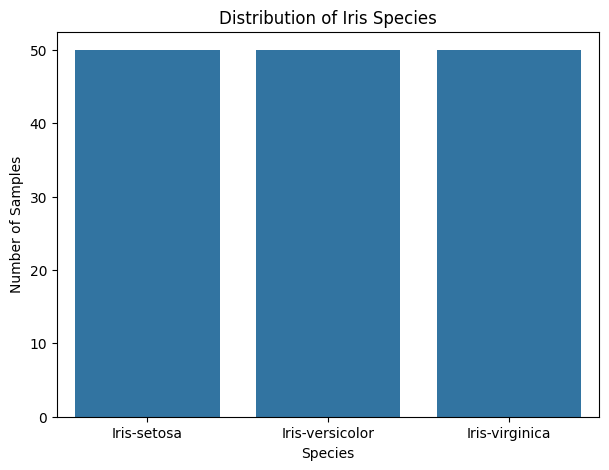

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")

plt.show()

# Feature Distribution (Histogram)

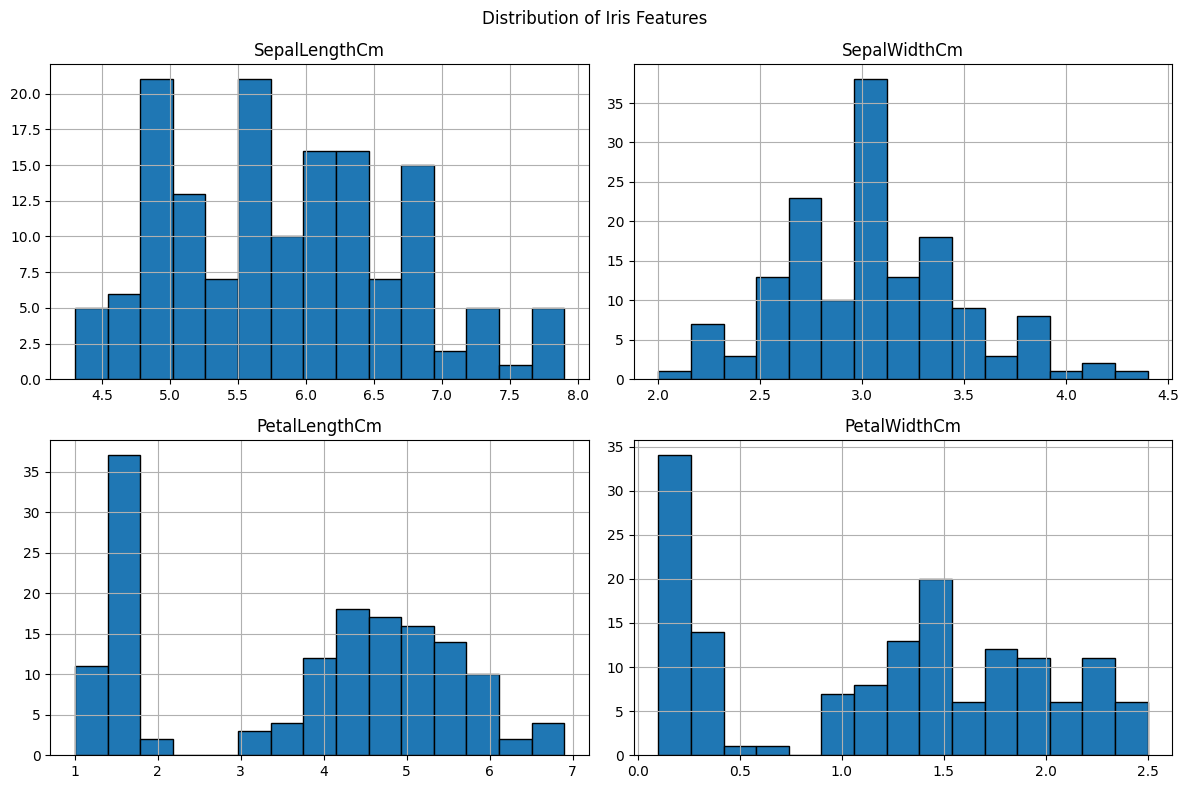

In [14]:

df[X.columns].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()


# Feature Relationship (Scatter Plot)

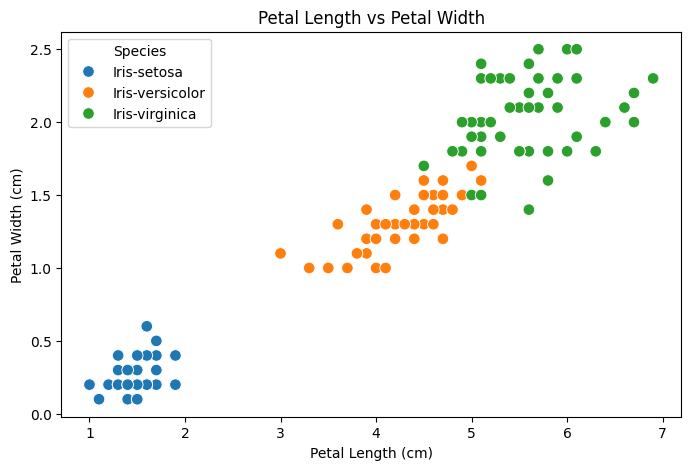

In [15]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    s=70
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()


# Pair Plot

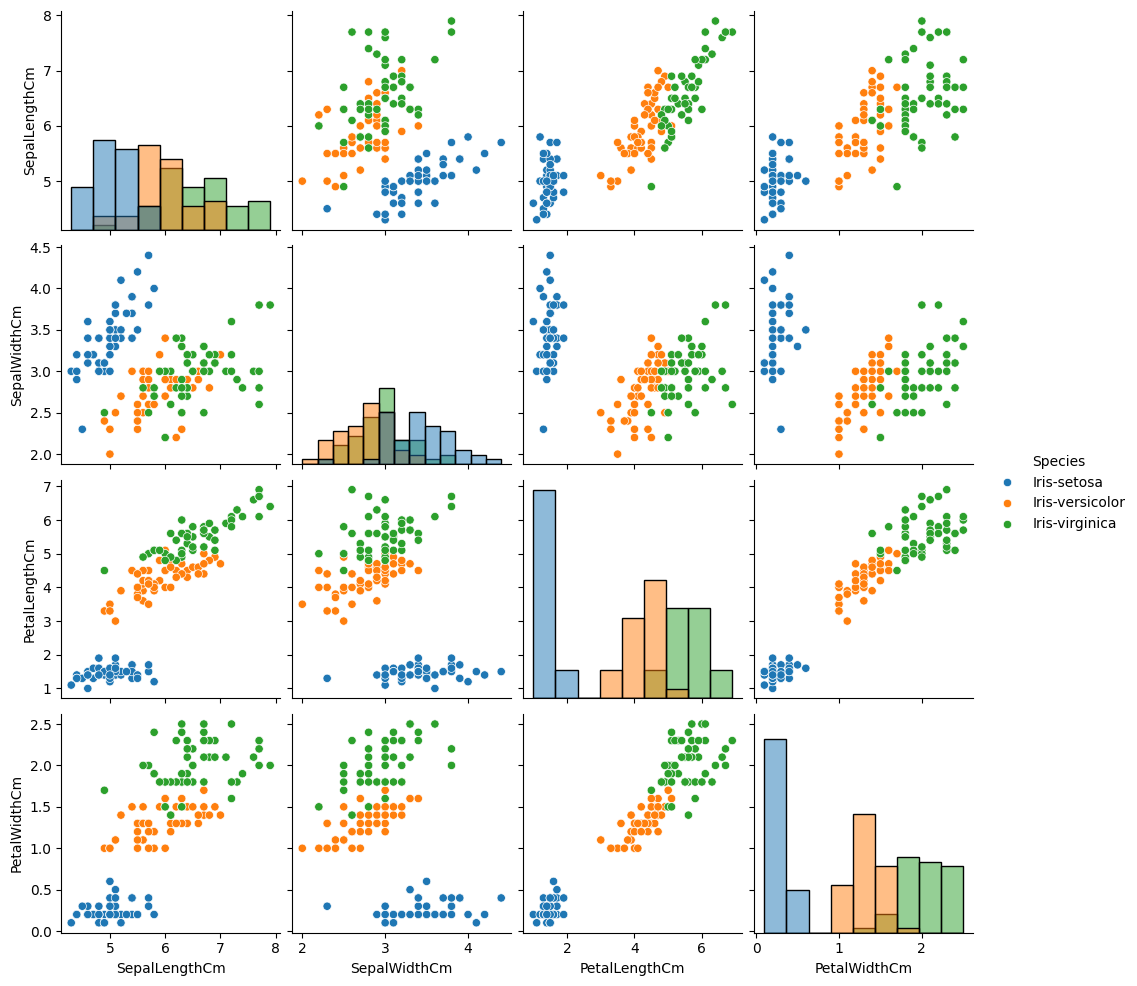

In [16]:
sns.pairplot(
    df,
    vars=X.columns,
    hue="Species",
    diag_kind="hist"
)

plt.show()


# Correlation Heatmap

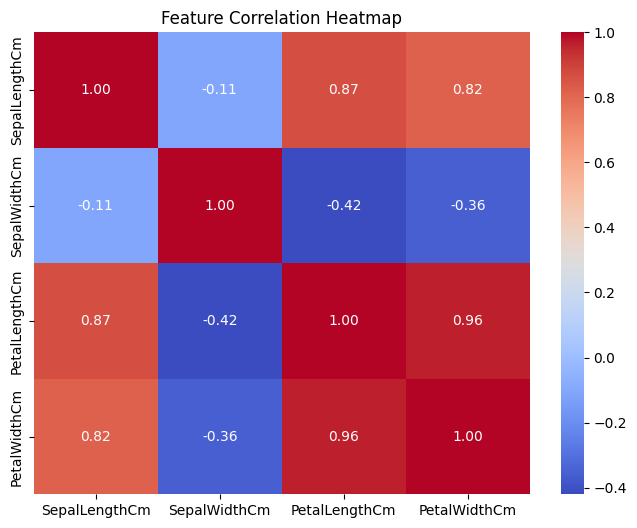

In [17]:
plt.figure(figsize=(8, 6))

correlation = X.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()
